<a href="https://colab.research.google.com/github/brooklynnsudler-collab/Brooklynn_INFO4670_Fall2026/blob/main/Sudler_INFO4670_Week3_Assignment1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 1 — Making Sense of Northgate through Visualization
**INFO 4670 · Data Analysis and Knowledge Discovery**  ·  **Due: Sunday, 11:59 PM**

**Name:** \_\_\_\_Brooklynn Sudler_\_\_    **Date:** \_\_\_08/01/26\_\_\_

**The situation.** The Provost's question stands: *which students are struggling, and can we see it earlier?* This week you answer it the way analysts do — not by reading rows, but by drawing the data. Every chart below is built by **adapting code from the Guided notebook**; the intellectual work is choosing the right chart and reading it honestly.

**For every chart you make, you must:**
1. **Choose** the chart type that fits the variable(s) and the question.
2. **Build** it in Colab from the Northgate files.
3. **Label** it fully — title, axis labels, and units/legend. *An unlabeled chart is an unfinished chart.*
4. **Write a STAR story** underneath it — Scope · Track · Articulate · Respond (defined on the Concepts deck).

**How to work:** run Setup and Load first. Then, for each question, copy the closest cell from the Guided notebook into the empty cell, adapt it, and fill in the STAR cell below it.

**Submit:** push this notebook to GitHub and submit the **GitHub link** in Canvas. (See the setup doc: *Colab_GitHub_Setup_INFO4670_Fall2026*.)

## Setup — run this first (you don't need to change it)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Northgate house style (optional, but keeps your charts consistent)
NAVY = "#22303A"
RUST = "#C0562F"
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"]   = (8, 5)
plt.rcParams["axes.titlesize"]   = 13
plt.rcParams["axes.titleweight"] = "bold"

## Load the data — run this, then look before you plot

In [2]:
# STEP 1 — get the data into this notebook. Pick ONE option, then run.

DATA_DIR = "."   # OPTION 2 (default) · drag the 3 CSVs into the file panel on the left

# OPTION 1 · read from Google Drive — uncomment and edit the path:
# from google.colab import drive
# drive.mount("/content/drive")
# DATA_DIR = "/content/drive/MyDrive/.../Data"

import os
students = pd.read_csv(os.path.join(DATA_DIR, "student_records.csv"))
weekly   = pd.read_csv(os.path.join(DATA_DIR, "weekly_activity.csv"))
students.head()

,student_id,major,age,housing,commute_miles,work_hours_per_week,advisor_meetings,credits_attempted,final_gpa,study_hours_reported,enrollment_date,dropped_out
0,NU-101508,Data Science,27,Off-Campus,7.6,15,1,81,1.86,NaN,2023-09-13,1
1,NU-102438,Learning Technologies,25,With Family,14.3,35,1,100,2.06,9.5,2023-10-19,0
2,NU-102385,Learning Technologies,26,With Family,3.4,18,9,77,3.41,19.1,11/16/2022,0
3,NU-100767,Cyber Security,22,On-Campus,23.7,40,1,65,1.73,8.1,2024-05-03,0
4,NU-106054,Information Technology,21,Off-Campus,2.3,20,4,59,2.37,6.6,10/24/2022,0


In [3]:
# how many rows, which columns, what types?
students.info() # 2027 rows, 12 columns, types: object, int64, float64

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2027 entries, 0 to 2026
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   student_id            2027 non-null   object 
 1   major                 2027 non-null   object 
 2   age                   2027 non-null   int64  
 3   housing               2027 non-null   object 
 4   commute_miles         2027 non-null   float64
 5   work_hours_per_week   2027 non-null   int64  
 6   advisor_meetings      2027 non-null   int64  
 7   credits_attempted     2027 non-null   int64  
 8   final_gpa             2027 non-null   float64
 9   study_hours_reported  1772 non-null   float64
 10  enrollment_date       2027 non-null   object 
 11  dropped_out           2027 non-null   int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 190.2+ KB


# Part A — Guided questions
Build **one chart per question**. Each maps to one chart family from this week. Copy the closest Guided-notebook cell, adapt it, label it, then write its STAR story.

### Q1 · One quantitative variable
**How many hours per week do Northgate students work?** Describe what's typical, how spread out it is, and whether anyone stands apart.
→ *histogram* (add a *box plot* if it helps). Column: `work_hours_per_week` (from `students`).

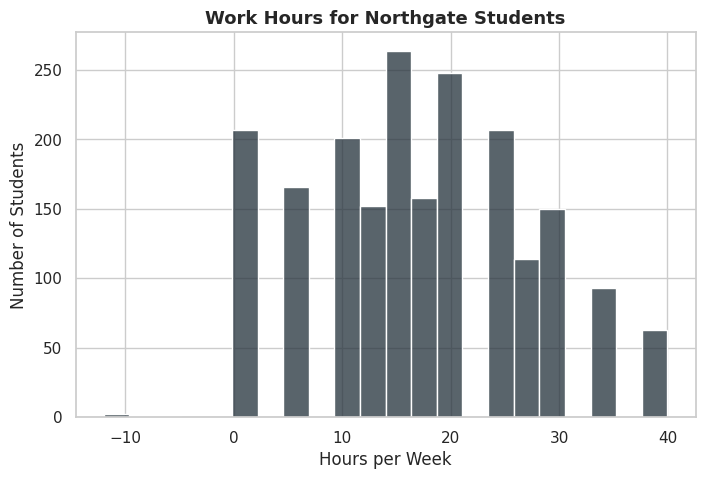

In [4]:
# Copy the closest cell from the Guided notebook, then fill in the blanks.
#
#   fig, ax = plt.subplots()
#   sns.__________(data=________, x="__________", color=NAVY, ax=ax)   # which chart? which column(s)?
#   ax.set_title("__________")
#   ax.set_xlabel("__________")
#   ax.set_ylabel("__________")
#   plt.show()

fig, ax = plt.subplots()
sns.histplot(data=students, x="work_hours_per_week", color=NAVY, ax=ax)
ax.set_title("Work Hours for Northgate Students")
ax.set_xlabel("Hours per Week")
ax.set_ylabel("Number of Students")
plt.show()


**STAR story — Q1** *(write in your own words)*

- **Scope —** what does this chart show? (which column(s), which students)
- **Track —** which question are you answering?
- **Articulate —** what does the chart actually say? (typical value, spread, shape, comparison, or trend)
- **Respond —** anything odd or unexpected? what would you look at next? *(note it — you don't fix it this week)*

**Scope:** The chart shows the relationship between the number of Northgate students and the hours they work per week.

**Track:** The question being answered by this chart is how many hours a week do Northgate students spend working.

**Articulate:** The histogram is mostly symmetrical with a slight skew to the right. Most students are shown to work about 15 hours per week week.

**Respond:** While this question does answer our initial question of how many hours a week do Northgate students spend working, a strong follow-up question that could be asked from this data is how these hours worked per week correlate to the grades and performance of the students. Does the amount of hours worked per week effect a student's academic performance?

### Q2 · One categorical variable
**How does enrollment compare across majors?**
→ *sorted bar chart*. Column: `major` (from `students`).

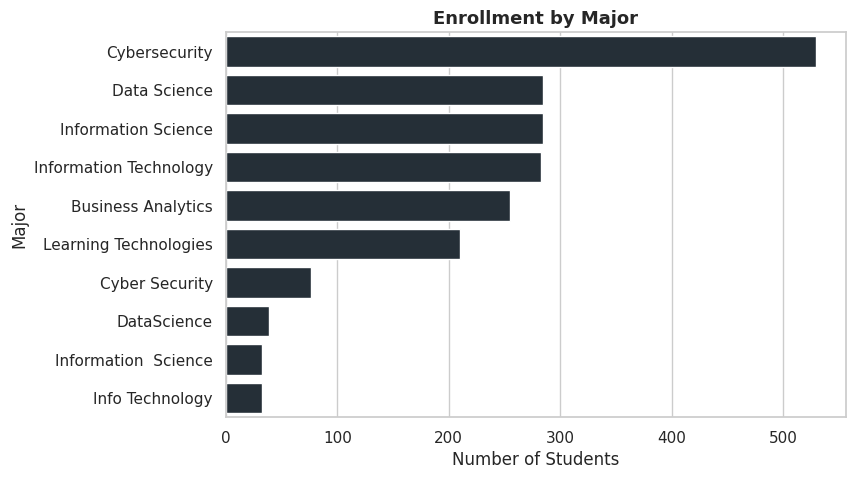

In [5]:
# Copy the closest cell from the Guided notebook, then fill in the blanks.
#
#   fig, ax = plt.subplots()
#   sns.__________(data=________, x="__________", color=NAVY, ax=ax)   # which chart? which column(s)?
#   ax.set_title("__________")
#   ax.set_xlabel("__________")
#   ax.set_ylabel("__________")
#   plt.show()

order = students["major"].value_counts().index
fig, ax = plt.subplots()
sns.countplot(data=students, y="major", order=order, color=NAVY, ax=ax)
ax.set_title("Enrollment by Major")
ax.set_xlabel("Number of Students")
ax.set_ylabel("Major")
plt.show()


**STAR story — Q2** *(write in your own words)*

- **Scope —** what does this chart show? (which column(s), which students)
- **Track —** which question are you answering?
- **Articulate —** what does the chart actually say? (typical value, spread, shape, comparison, or trend)
- **Respond —** anything odd or unexpected? what would you look at next? *(note it — you don't fix it this week)*

**Scope:** The chart shows the number of Northgate students in each major.

**Track:** The question the chart is answering is how does enrollment compare across majors at Northgate.

**Articulate:** The data shows that most students are enrolled in Cybersecurity followed by Data Science, Information Science, and Information Technology.

**Respond:** A problem I spotted from the chart is that part of the data from Cybersecurity, Data Science, Information Science, Information Technology are separated due to spacing errors. This messes up the overall count of the student enrollment in each major.

### Q3 · A quantity, split by category
**Does final GPA differ across majors?** Read the exceptions, not just the boxes.
→ *box plot per major*. Columns: `final_gpa` and `major` (from `students`).

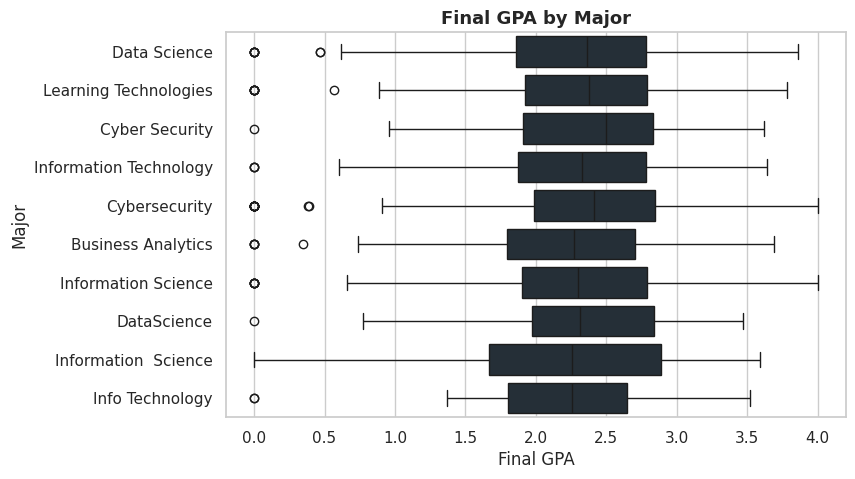

In [6]:
# Copy the closest cell from the Guided notebook, then fill in the blanks.
#
#   fig, ax = plt.subplots()
#   sns.__________(data=________, x="__________", color=NAVY, ax=ax)   # which chart? which column(s)?
#   ax.set_title("__________")
#   ax.set_xlabel("__________")
#   ax.set_ylabel("__________")
#   plt.show()

fig, ax = plt.subplots()
sns.boxplot(data=students, x="final_gpa", y="major", color=NAVY, ax=ax)
ax.set_title("Final GPA by Major")
ax.set_xlabel("Final GPA")
ax.set_ylabel("Major")
plt.show()



**STAR story — Q3** *(write in your own words)*

- **Scope —** what does this chart show? (which column(s), which students)
- **Track —** which question are you answering?
- **Articulate —** what does the chart actually say? (typical value, spread, shape, comparison, or trend)
- **Respond —** anything odd or unexpected? what would you look at next? *(note it — you don't fix it this week)*

**Scope:** The chart shows the range of final GPAs of Northgate students by major.

**Track:** The question being answered by the chart is if final GPA differ across majors for Northgate students.

**Articulate:** The range of values across the majors seem to fall under the same range. The mediam final GPA across all majors seems to be about 2.5.

**Respond:** I notice the same issue as the prior chart that the data for certain majors are split due to spacing errors in the names of the majors.

### Q4 · Two quantitative variables
**Is there a relationship between how far students commute and their final GPA?** Remember: *association is not causation.*
→ *scatterplot with a trend line*. Columns: `commute_miles` and `final_gpa` (from `students`).

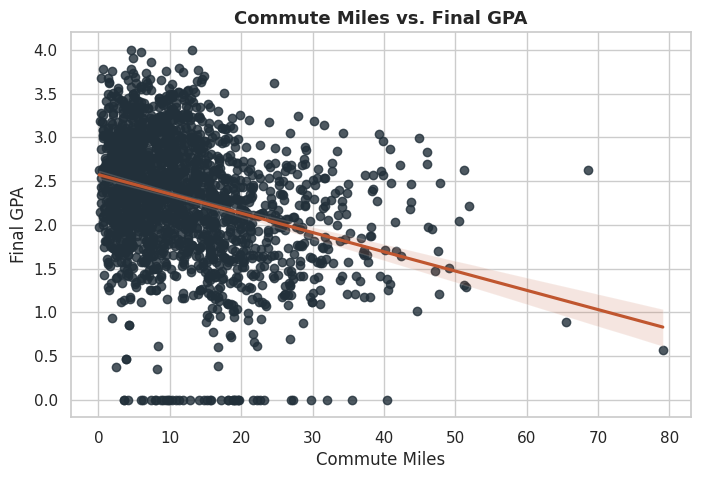

In [7]:
# Copy the closest cell from the Guided notebook, then fill in the blanks.
#
#   fig, ax = plt.subplots()
#   sns.__________(data=________, x="__________", color=NAVY, ax=ax)   # which chart? which column(s)?
#   ax.set_title("__________")
#   ax.set_xlabel("__________")
#   ax.set_ylabel("__________")
#   plt.show()

fig, ax = plt.subplots()
sns.regplot(data=students, x="commute_miles", y="final_gpa",
            scatter_kws={"color": NAVY},
            line_kws={"color": RUST}, ax=ax)
ax.set_title("Commute Miles vs. Final GPA")
ax.set_xlabel("Commute Miles")
ax.set_ylabel("Final GPA")
plt.show()


**STAR story — Q4** *(write in your own words)*

- **Scope —** what does this chart show? (which column(s), which students)
- **Track —** which question are you answering?
- **Articulate —** what does the chart actually say? (typical value, spread, shape, comparison, or trend)
- **Respond —** anything odd or unexpected? what would you look at next? *(note it — you don't fix it this week)*

**Scope:** The scatterplot chart shows the relationship between commute time in miles and final GPAs of Northgate students.

**Track:** The question the chart is answering is if there is a relationship between how far students have to commute to school and their final GPA results. Does their commute affect their academic performance?

**Articulate:** The final GPA drifts downwards as the commute miles increases. Students with less of a commute have relatively higher GPA scores while those with a longer commute have lower GPA scores.

**Respond:** Nothing unexpected jumps out to me. There are some slight outliers, but nothing too peculiar that would need to be assessed.

### Q5 · Over time
**How does student engagement change across the semester?**
→ *line chart* of average weekly activity. Use the `weekly` table: `week` and `minutes_active` (you'll need to average by week first — see the Guided notebook).

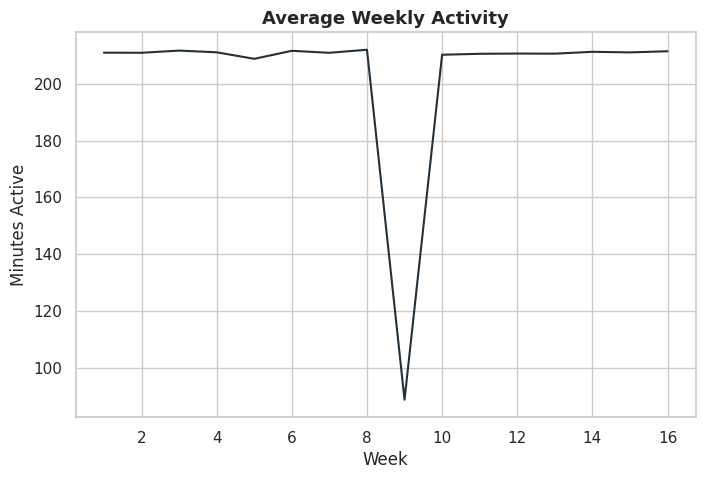

In [8]:
# Copy the closest cell from the Guided notebook, then fill in the blanks.
#
#   fig, ax = plt.subplots()
#   sns.__________(data=________, x="__________", color=NAVY, ax=ax)   # which chart? which column(s)?
#   ax.set_title("__________")
#   ax.set_xlabel("__________")
#   ax.set_ylabel("__________")
#   plt.show()

weekly_avg = weekly.groupby("week")["minutes_active"].mean().reset_index()
fig, ax = plt.subplots()
sns.lineplot(data=weekly_avg, x="week", y="minutes_active",
             color=NAVY, ax=ax)
ax.set_title("Average Weekly Activity")
ax.set_xlabel("Week")
ax.set_ylabel("Minutes Active")
plt.show()


**STAR story — Q5** *(write in your own words)*

- **Scope —** what does this chart show? (which column(s), which students)
- **Track —** which question are you answering?
- **Articulate —** what does the chart actually say? (typical value, spread, shape, comparison, or trend)
- **Respond —** anything odd or unexpected? what would you look at next? *(note it — you don't fix it this week)*

**Scope:** The line chart shows the weekly activity of Northgate students over time.

**Track:** The question that the chart answers is if student engagement changes across the semester.

**Articulate:** The trend stays very consistant week by week besides a large dip around the 9th week.

**Respond:** The only thing that stands out to me is the dip on week 9, but this coudld be due to maybe a holiday break or something similar where students were not active on campus.

# Part B — Your own question (open)
Pose **one question of your own** about the Northgate students, choose the chart that answers it, build it, label it, and write its STAR story. Going beyond Part A is rewarded — a per-student line chart, a violin plot, or a chart of a messier column are all fair game.

**Your question:** \_\_Is there a relationship between the time students spend studying and thier final GPA?\_\_\_



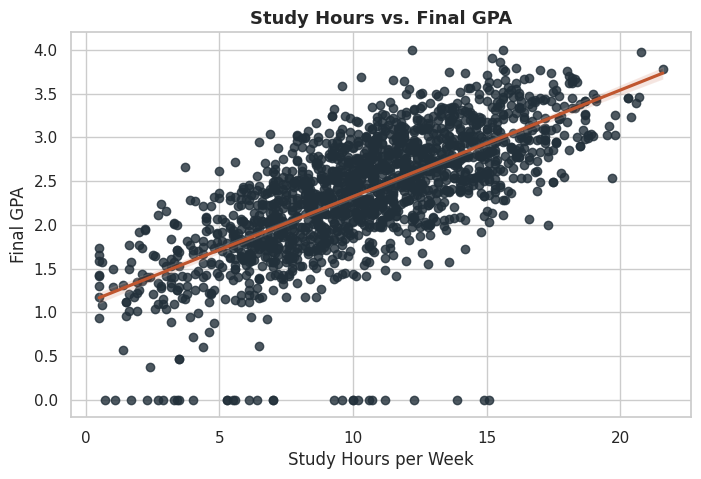

In [9]:
# Copy the closest cell from the Guided notebook, then fill in the blanks.
#
#   fig, ax = plt.subplots()
#   sns.__________(data=________, x="__________", color=NAVY, ax=ax)   # which chart? which column(s)?
#   ax.set_title("__________")
#   ax.set_xlabel("__________")
#   ax.set_ylabel("__________")
#   plt.show()

fig, ax = plt.subplots()
sns.regplot(data=students, x="study_hours_reported", y="final_gpa",
            scatter_kws={"color": NAVY},
            line_kws={"color": RUST}, ax=ax)
ax.set_title("Study Hours vs. Final GPA")
ax.set_xlabel("Study Hours per Week")
ax.set_ylabel("Final GPA")
plt.show()


**STAR story — Part B** *(write in your own words)*

- **Scope —** what does this chart show? (which column(s), which students)
- **Track —** which question are you answering?
- **Articulate —** what does the chart actually say? (typical value, spread, shape, comparison, or trend)
- **Respond —** anything odd or unexpected? what would you look at next? *(note it — you don't fix it this week)*

**Scope:** The scatterplot shows the relationship between the reported time in hours that Northgate students spend studying and the their final GPA.

**Track:** The question being answered is if there is a relationship between hours spent studying and final GPA results.

**Articulate:** The chart shows a very strong ascending trendline where Final GPA steadily increases as Study Hours per Week also steadily increases.

**Respond:** Nothing unexpected stands out to me from this graph. I think it shows a possible correlation of the two variables which could possible provide an answer to the question being asked.

# Before you submit — checklist
- [ ] The notebook **runs top to bottom** with no errors (Runtime → Restart and run all).
- [ ] All **6 charts** are present, each with a title, labeled axes, and units/legend where needed.
- [ ] Each chart has a **complete STAR story**, including any exceptions you spotted.
- [ ] Part B question is written in and answered.
- [ ] Pushed to **GitHub**, and the **GitHub link** is submitted in Canvas.

**Rubric (70 pts):** chart choice 10 · correct build 20 · labeling 10 · STAR reading 18 · Part B question 4 · submission & professionalism 8.